CDS 230 - Lab 5: K-means Clustering

Student 1: Doungmin Shin
Student 2: Seunghyun Park

Dataset: Online Shoppers intention

URL: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [4]:
print(df.shape)

(12330, 18)


In [5]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [6]:
#remove the missing values with NaNs
df = df.dropna(subset=['Administrative_Duration', 'ProductRelated_Duration'])
print(df.shape)

(12330, 18)


Text(0, 0.5, 'Product-related page duration')

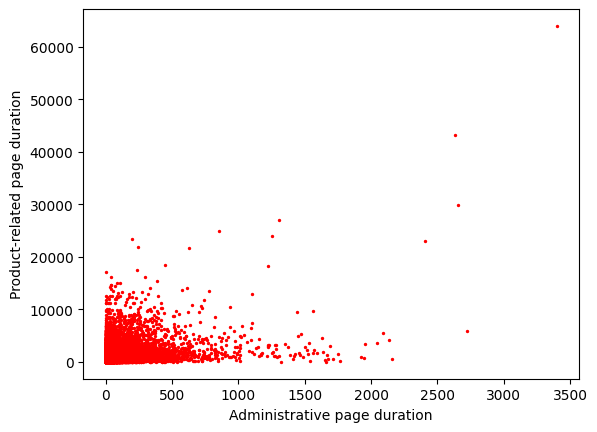

In [7]:
# scatter plot
plt.scatter(df['Administrative_Duration'], df['ProductRelated_Duration'], c='red', s=2)
plt.xlabel('Administrative page duration')
plt.ylabel('Product-related page duration')

In [8]:
# For now, we'll try k value 2
k = 2
X = np.array(list(zip(df['Administrative_Duration'], df['ProductRelated_Duration'])))
model = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans = model.fit(X)
labels = model.predict(X)
centroids = model.cluster_centers_

print(labels)
print(centroids)

[0 0 0 ... 0 0 0]
[[  70.44068059  794.6722697 ]
 [ 208.18005228 6104.58810049]]


Text(0, 0.5, 'Product-related page duration')

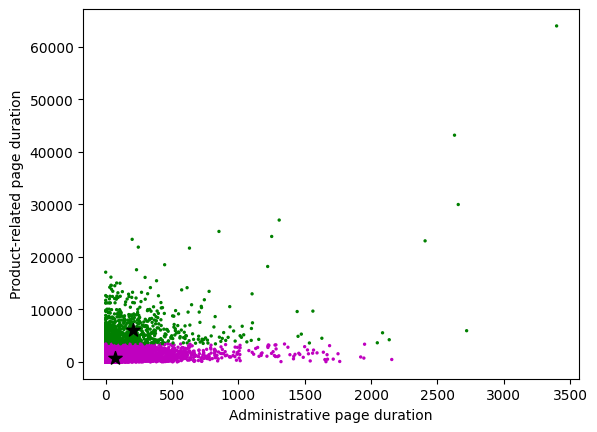

In [9]:
# Plot the data and centroids on a scatter plot
# map the labels to colors
c = ['m', 'g', 'b', 'r', 'y', 'c']
colors = [c[i] for i in labels]

plt.scatter(df['Administrative_Duration'], df['ProductRelated_Duration'], c=colors, s=2)
plt.scatter(centroids[:, 0], centroids[:, 1], marker='*', s=100, c='black')
plt.xlabel('Administrative page duration')
plt.ylabel('Product-related page duration')

In [10]:
# Using the model that you have just trained,
# you can use it to predict what cluster for any data point
cluster = model.predict([[35, 123]])[0]
print(c[cluster])

m


In [11]:
# To determine the silhouette coefficient/score
from sklearn.metrics import silhouette_score

model = KMeans(n_clusters=2, random_state=42, n_init=10)
model.fit(X)
label = model.predict(X)
print(f'silhouette Score (n=2): {silhouette_score(X, label, sample_size=3000, random_state=42)}')

model = KMeans(n_clusters=3, random_state=42, n_init=10)
model.fit(X)
label = model.predict(X)
print(f'silhouette Score (n=3): {silhouette_score(X, label, sample_size=3000, random_state=42)}')

model = KMeans(n_clusters=4, random_state=42, n_init=10)
model.fit(X)
label = model.predict(X)
print(f'silhouette Score (n=4): {silhouette_score(X, label, sample_size=3000, random_state=42)}')

silhouette Score (n=2): 0.7809270389773353
silhouette Score (n=3): 0.7110828831465204
silhouette Score (n=4): 0.6902001632429853


[[   58.14334311   516.57393717]
 [  227.49467913  8304.13787295]
 [  147.61250397  2840.0256861 ]
 [ 1558.19630558 30277.952413  ]]


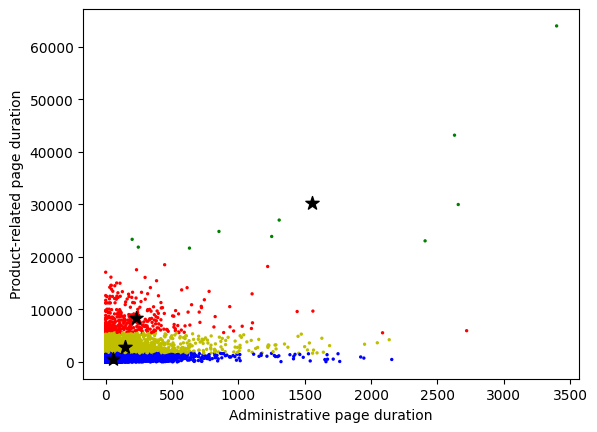

In [12]:
k = 4
X = np.array(list(zip(df['Administrative_Duration'], df['ProductRelated_Duration'])))

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans = kmeans.fit(X)
labels = kmeans.predict(X)
centroids = kmeans.cluster_centers_

# map the labels to colors
c = ['b', 'r', 'y', 'g', 'c', 'm']
colors = [c[i] for i in labels]

plt.scatter(df['Administrative_Duration'], df['ProductRelated_Duration'], c=colors, s=2)
plt.scatter(centroids[:, 0], centroids[:, 1], marker='*', s=100, c='black')
plt.xlabel('Administrative page duration')
plt.ylabel('Product-related page duration')
print(centroids)

In this exercise, we use the Administrative_Duration and ProductRelated_Duration variables from the Online Shoppers Intention dataset. We apply K-Means with different numbers of clusters (2, 3, and 4) and compare their silhouette scores to evaluate cluster separation. The cluster labels identify each data point's group, while the centroids represent the centers of the clusters. Finally, we examine four clusters to explore different patterns of online shopping behavior.
